(model-diagnostics)=
# Model Diagnostics and Summary

### Model Summary

Access detailed model summary information including parameter estimates, standard errors, and model fit statistics.

<br>

**Examples:**

In [9]:
from rpy2.robjects.packages import importr
import rpy2.robjects as robjects
base = importr('base')

model_summary = base.summary(robjects.r[model_name])
print(model_summary)

******************************************************************
Family:  c("SHASH", "Sinh-Arcsinh") 

Call:  gamlss(formula = y_thickness1 ~ pvc(age, by = as.factor(sex)) +  
    re(random = ~1 | as.factor(site)), sigma.formula = ~pvc(age) +  
    re(random = ~1 | as.factor(site)), nu.formula = ~1, tau.formula = ~1,  
    family = SHASH(), data = model_shash_traindata, method = mixed(10,  
        100)) 

Fitting method: mixed(10, 100) 

------------------------------------------------------------------
Mu link function:  identity
Mu Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) 23.49569    0.03165   742.5   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

------------------------------------------------------------------
Sigma link function:  log
Sigma Coefficients:
             Estimate Std. Error t value Pr(>|t|)    
(Intercept) 2.7086019  0.0583874  46.390   <2e-16 ***
pvc(age)    0.0000651  0.0011069   0.059    0.95

### Random Effects Analysis

Examine random effects parameters to understand model shrinkage and site-specific variations.

<br>

**Examples:**

In [10]:
# Analyze random effects parameters
comparison = robjects.r('''
# Create a comparison list of key parameters
list(
    # 1. Lambda value - high value indicates random effects shrinkage
    lambda = model_shash$mu.lambda,
    
    # 2. Effective degrees of freedom
    mu_df = model_shash$mu.df,
    
    # 3. Number of site parameters vs effective df
    site_params = length(model_shash$mu.coefficients[grep("site", names(model_shash$mu.coefficients))]),
    
    # 4. Site coefficient values (to check shrinkage)
    site_values = model_shash$mu.coefficients[grep("site", names(model_shash$mu.coefficients))],
    
    # 5. Whether random effects were specified
    random_specified = grepl("random", capture.output(model_shash$call))
)
''')
print(comparison)

R[write to console]: In summary.gamlss(list(family = c("SHASH", "Sinh-Arcsinh"), parameters = c("mu",  :
R[write to console]:  summary: vcov has failed, option qr is used instead




$lambda
[1] 346.003626   1.000273

$mu_df
[1] 7.951792

$site_params
[1] 1

$site_values
re(random = ~1 | as.factor(site)) 
                               NA 

$random_specified
[1] FALSE  TRUE  TRUE FALSE FALSE




### gamlss_main.Gamlss.<br>**plot_diagnostics**

```python
plot_diagnostics(save_image=None, file_name=None, dpi=300, save_pdf=False, axs=None)
```

&nbsp;&nbsp;&nbsp;&nbsp;Creates a 2x2 grid of diagnostic plots including: (1) Residuals vs Fitted Values: Checks for heteroscedasticity and non-linearity, (2) Residuals vs Index: Identifies systematic patterns or outliers, (3) Density Estimate: Shows distribution of quantile residuals with rug plot, (4) Normal Q-Q Plot: Assesses normality of residuals.

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Parameters:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**save_image** : ***str***, *optional* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Folder path to save the image (default is None)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**file_name** : ***str***, *optional* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;File name for the saved image (default is None)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**dpi** : ***int***, *default=300* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;DPI for the saved image

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**save_pdf** : ***bool***, *default=False* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;If True, additionally saves a vector .pdf copy alongside the primary saved image.

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**axs** : ***2x2 array-like of matplotlib.axes.Axes***, *optional* <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Existing 2x2 grid of Axes to draw the four panels into, for composing this into your own figure, e.g. `fig, axs = plt.subplots(2, 2); model.plot_diagnostics(axs=axs)`. <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;If provided, draws into it instead of creating its own figure, and skips `plt.show()`/saving (you control display and saving). If None (default), behavior is unchanged.

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Returns:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**(fig, axs)** : ***(matplotlib.figure.Figure, numpy.ndarray)*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;The Figure and the 2x2 array of Axes used, so you can keep customizing after this call (e.g. `axs[0, 0].set_ylim(...)`, `fig.savefig(...)`).

<br>

**Examples:**

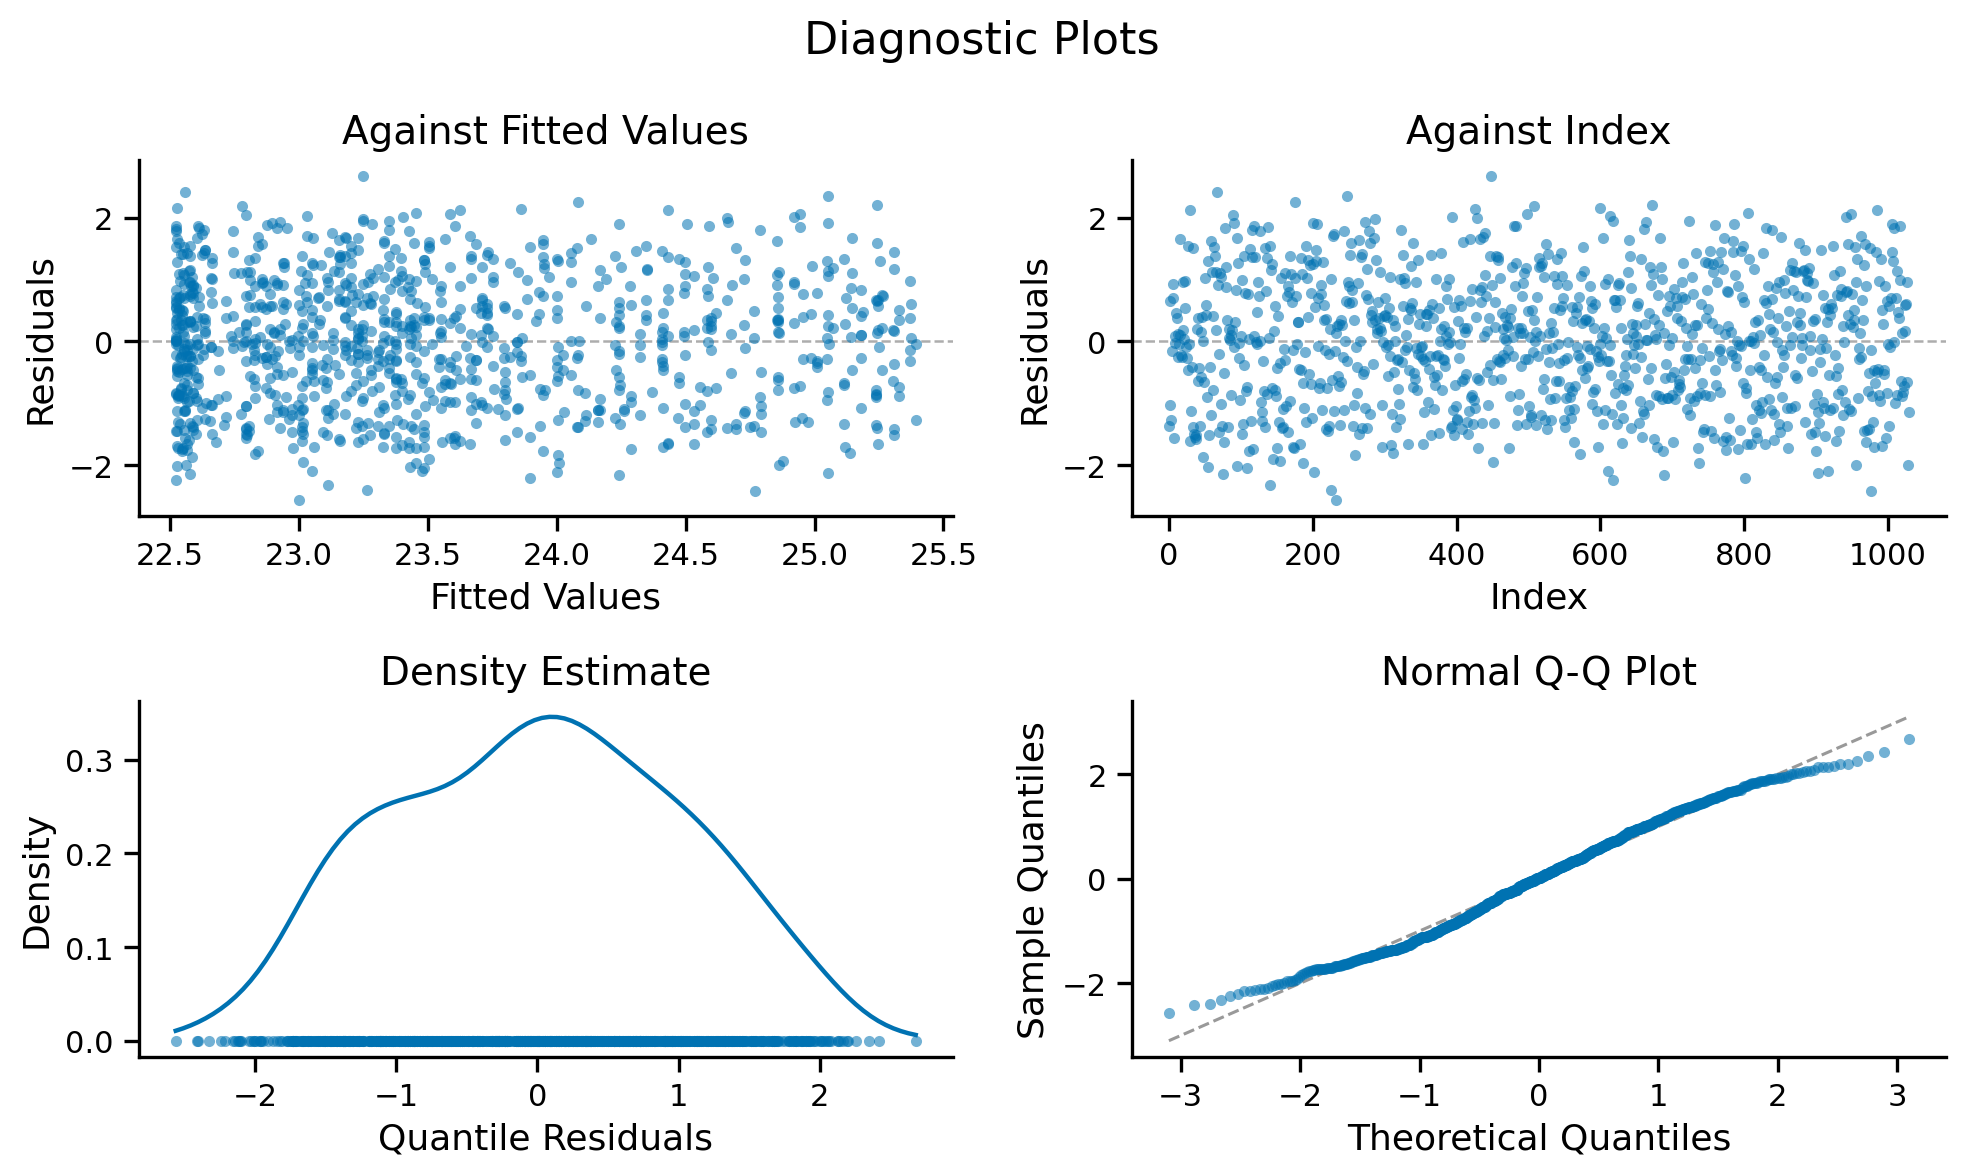

******************************************************************
	      Summary of the Quantile Residuals
                           mean   =  0.00150161 
                       variance   =  1.062349 
               coef. of skewness  =  0.005728379 
               coef. of kurtosis  =  2.240857 
Filliben correlation coefficient  =  0.9943954 
******************************************************************
2


In [11]:
gamlss_model.plot_diagnostics();

### gamlss_main.Gamlss.<br>**gamlss_diagnostic_plot**

```python
gamlss_diagnostic_plot()
```

&nbsp;&nbsp;&nbsp;&nbsp;Generates R's built-in GAMLSS diagnostic plots and displays them in the notebook. Provides additional diagnostic information beyond the Python implementation.

&nbsp;&nbsp;&nbsp;&nbsp;Takes no arguments beyond the fitted model itself.

&nbsp;&nbsp;&nbsp;&nbsp;<span style="background-color: #f5f5f5; padding: 4px 8px; display: inline-block; width: 90%;">**Returns:**</span>

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**None** : ***None*** <br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;Displays R's native diagnostic plots

<br>


**Examples:**

******************************************************************
	      Summary of the Quantile Residuals
                           mean   =  0.00150161 
                       variance   =  1.062349 
               coef. of skewness  =  0.005728379 
               coef. of kurtosis  =  2.240857 
Filliben correlation coefficient  =  0.9943954 
******************************************************************


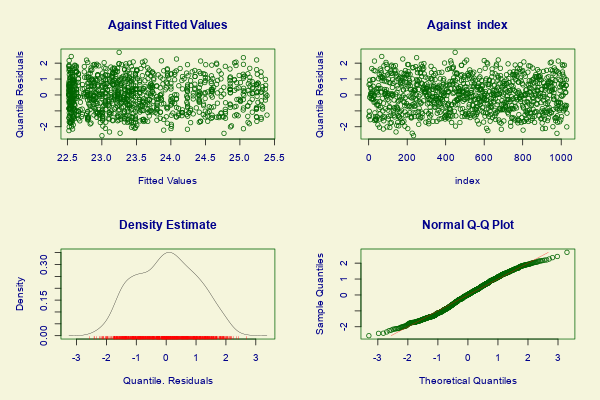

In [12]:
# Display R's native diagnostic plots
gamlss_model.gamlss_diagnostic_plot()